# Exercise 09 — Evaluating Generated Text

Last week you generated text with greedy search, beam search and sampling, and you judged the results mostly by reading them, with the log-probability and distinct-n as rough numbers on the side. That does not scale: to compare two translation systems, or to check whether a new summariser is better than the old one, you need a number that you can compute for thousands of outputs, and that agrees with what people think of them.

That is harder than it sounds. A question like *"What is the capital of Denmark?"* has one right answer, but a sentence has many good translations, and an article has countless good summaries. An automatic metric compares a generated text with one or a few **reference** texts written by people, and has to decide how "close" it is.

This week has three notebooks:

- **Evaluating generated text** (this notebook): the classic metrics BLEU and ROUGE, the model-based BERTScore, and how to find out whether a metric can be trusted.
- **Question answering** (notebook 1): extractive QA with a BERT-style model, generative QA with a small chat model, and the metrics for both.
- **Retrieval-augmented generation** (notebook 2): finding the right documents with BM25 and dense embeddings, and letting an LLM answer from them.

## What you will do
1. **BLEU**: clipped n-gram precision and the brevity penalty, implemented by hand and checked against `sacrebleu`.
2. **ROUGE**: n-gram recall and the longest common subsequence, checked against `rouge-score`.
3. **Where overlap metrics fail**: paraphrases and negations.
4. **BERTScore**: matching tokens by their contextual embeddings.
5. **Can we trust a metric?**: correlating metrics with human judgements of summaries (SummEval).
6. **Multiple-choice questions**: to check your understanding.

## How to work through it
- Run the cells **in order** and fill in **every `# TODO`**.
- Tasks are numbered (**1.1**, **1.2**, …). Tasks that say *Your answer here* want a short written answer, not code.
- Most implementation tasks are followed by a **✅ Check** cell that verifies your work automatically. Run it and make sure it passes before you move on.

> **Heads up: this notebook downloads DistilBERT** (~270 MB, still cached if you did week 7) and the SummEval dataset (~1 MB). Everything runs on a CPU; Part 5 takes about a minute.

In [1]:
import scipy.stats
%matplotlib inline
import math
import re
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import sacrebleu
import torch
import torch.nn.functional as F
from datasets import load_dataset
from rouge_score import rouge_scorer
from scipy.stats import kendalltau
from transformers import AutoModel, AutoTokenizer

torch.manual_seed(0)

## 1. BLEU

**BLEU** (*Bilingual Evaluation Understudy*; [Papineni et al., 2002](https://aclanthology.org/P02-1040/)) was designed for machine translation, and you used it in week 5 to score the English–French model. The idea: a good translation shares many words and short phrases with a human translation. BLEU counts how many of the **n-grams** (sequences of *n* tokens, for *n* = 1 to 4) of the generated text also occur in the reference.

Throughout this part, texts are already lower-cased and tokenized, so we can split them on spaces.

### Clipped n-gram precision

A naive precision, "the fraction of generated n-grams that occur in the reference", is easy to fool: the candidate `the the the the` has a unigram precision of 100 % against `the cat is on the mat`. BLEU therefore **clips** every count: an n-gram is only counted as often as it occurs in the reference. `the` occurs twice in the reference, so only two of the four `the`s count, and the clipped precision is 2/4.

**1.1 Complete `ngrams` and `clipped_matches`.**

Hint: `Counter` counts the elements of a list, and `counter_a[key]` is 0 for a missing key.

In [20]:
def ngrams(tokens: str, n: int) -> Counter[str]:
    # A Counter of all n-grams (as tuples) in a list of tokens
    return Counter(tuple(tokens[i:i+n]) for i in range(len(tokens) - n + 1))  # TODO


def clipped_matches(candidate, reference, n):
    # (number of clipped n-gram matches, number of n-grams in the candidate), for lists of tokens
    cand, ref = ngrams(candidate, n), ngrams(reference, n)
    matches = sum(min(v, ref[k]) for (k, v) in cand.items())  # TODO: every n-gram of the candidate counts at most as often as it occurs in the reference
    total = sum(cand.values())    # TODO: the number of n-grams in the candidate
    return matches, total


reference = "the cat is on the mat".split()
for candidate in ["the the the the", "the cat sat on the mat", "on the mat the cat is"]:
    print(f"{candidate!r:26}", [clipped_matches(candidate.split(), reference, n) for n in [1, 2, 3, 4]])

'the the the the'          [(2, 4), (0, 3), (0, 2), (0, 1)]
'the cat sat on the mat'   [(5, 6), (3, 5), (1, 4), (0, 3)]
'on the mat the cat is'    [(6, 6), (4, 5), (2, 4), (0, 3)]


In [21]:
# ✅ Check ngrams and clipped_matches
assert ngrams("a b a b".split(), 2) == Counter({("a", "b"): 2, ("b", "a"): 1}), "ngrams('a b a b', 2) should count ('a', 'b') twice and ('b', 'a') once"
assert clipped_matches("the the the the".split(), reference, 1) == (2, 4), "'the' occurs only twice in the reference"
assert clipped_matches("the cat sat on the mat".split(), reference, 2) == (3, 5)
assert clipped_matches("a b".split(), "a b".split(), 3) == (0, 0), "a text with fewer than n tokens has no n-grams"
print("Looks good ✅")

Looks good ✅


### The brevity penalty and the full BLEU score

Precision alone rewards texts that say very little: the candidate `the cat` has perfect unigram and bigram precision. BLEU does not use recall (with several references, it is unclear what recall should mean). Instead it multiplies the score by a **brevity penalty** that punishes candidates that are shorter than the reference:

$$\text{BP} = \begin{cases} 1 & \text{if } c > r \\ e^{\,1 - r/c} & \text{if } c \le r \end{cases} \qquad\qquad \text{BLEU} = \text{BP} \cdot \exp\Big(\frac{1}{4}\sum_{n=1}^{4} \log p_n\Big)$$

where $c$ is the length of the candidates and $r$ the length of the references, and $p_n$ is the clipped n-gram precision. The second factor is the **geometric mean** of the four precisions.

An important detail: BLEU is a **corpus-level** metric. The matches, n-gram counts and lengths are summed over *all* sentences of the test set first, and only then are the precisions and the score computed. It is not the average of the BLEU scores of the sentences.

**1.2 Complete `corpus_bleu`** for a list of candidates with one reference each (both as strings). If any of the four precisions is 0, the geometric mean is 0, so return 0.0 in that case. The function returns the score between 0 and 1; tools usually report it multiplied by 100.

In [22]:
def corpus_bleu(candidates, references, max_n=4):
    # Corpus BLEU (between 0 and 1) of a list of candidate strings, with one reference string each
    matches, totals = [0] * max_n, [0] * max_n
    cand_length, ref_length = 0, 0
    for candidate, reference in zip(candidates, references):
        candidate, reference = candidate.split(), reference.split()
        # TODO: add up the lengths, and the clipped matches and n-gram counts for n = 1, ..., max_n
        cand_length += len(candidate)
        ref_length += len(reference)
        for n in range(1, max_n + 1):
            m, t = clipped_matches(candidate, reference, n)
            matches[n-1] += m
            totals[n-1] += t

    precisions = [m / t if t > 0 else 0.0 for m, t in zip(matches, totals)]  # TODO: the clipped precision p_n for every n
    if min(precisions) == 0:
        return 0.0
    brevity_penalty = 1 if cand_length > ref_length else math.exp(1 - ref_length / cand_length)  # TODO
    return brevity_penalty * math.exp(sum(math.log(p) for p in precisions) / max_n)  # TODO: the brevity penalty times the geometric mean of the precisions


candidates = ["the cat is on the mat today", "there is a cat sitting on the carpet"]
references = ["the cat sits on the mat today", "a cat is sitting on the carpet near the door"]
print(f"BLEU: {100 * corpus_bleu(candidates, references):.2f}")

BLEU: 39.88


[`sacrebleu`](https://github.com/mjpost/sacrebleu) ([Post, 2018](https://aclanthology.org/W18-6319/)) is the standard implementation, which you already used in week 5. By default it applies its own tokenization and a smoothing for zero counts. We switch both off to compare it with your version:

In [28]:
# ✅ Check corpus_bleu against sacrebleu
def sacre(candidates, references):
    return sacrebleu.corpus_bleu(candidates, [references], tokenize="none", smooth_method="none", force=True).score


tests = [
    (candidates, references),
    (["the cat is on the mat"], ["the cat is on the mat"]),
    (["on the mat the cat is"], ["the cat is on the mat"]),
    (["the cat is on the mat and the dog is too"], ["the cat is on the mat"]),
    (["the cat"], ["the cat is on the mat"]),
]
for cands, refs in tests:
    mine, theirs = 100 * corpus_bleu(cands, refs), sacre(cands, refs)
    assert abs(mine - theirs) < 1e-6, f"for {cands} your BLEU is {mine:.4f}, sacrebleu says {theirs:.4f}"
print("Looks good ✅")

print(f"{corpus_bleu(["the cat"], ["the cat is on the mat"]) = }")

Looks good ✅
corpus_bleu(["the cat"], ["the cat is on the mat"]) = 0.0


**1.3 Short candidates.** `"the cat"` against `"the cat is on the mat"` has perfect 1- and 2-gram precision, but `corpus_bleu(["the cat"], ["the cat is on the mat"])` is 0 (try it). Why? And what would its score be if the brevity penalty were the only problem? Why would a metric based on precision alone be a bad target for a translation system to optimise?

---

*Your answer here:*

---

## 2. ROUGE

**ROUGE** (*Recall-Oriented Understudy for Gisting Evaluation*; [Lin, 2004](https://aclanthology.org/W04-1013/)) is the standard metric for **summarisation**. Where BLEU asks "how much of what the system wrote is in the reference?", ROUGE was designed to ask the opposite: **how much of the reference did the system cover?** Today the F1 score, which combines both, is reported most often. The variants:

- **ROUGE-1** and **ROUGE-2**: the overlap of unigrams and bigrams, with clipped counts as in BLEU. Precision divides the matches by the number of n-grams of the prediction, recall by the number of n-grams of the reference.
- **ROUGE-L**: based on the **longest common subsequence** (LCS): the longest sequence of tokens that occurs in both texts in the same order, but not necessarily next to each other. `the cat on mat` is a common subsequence of `the cat is on the mat` and `the black cat sat on a mat`. Precision is the length of the LCS divided by the length of the prediction, recall divided by the length of the reference. ROUGE-L rewards the right word order without requiring exact n-grams.

The reference implementation, Google's [`rouge-score`](https://github.com/google-research/google-research/tree/master/rouge), lower-cases the text and replaces everything that is not a letter or a digit by a space. The function `tokenize` below does the same.

**2.1 Complete `rouge_n`** (reuse `ngrams` from Part 1) **and `lcs_length`**, the length of the longest common subsequence.

Hint for the LCS: the classic dynamic programme fills a table in which `table[i][j]` is the length of the LCS of the first `i` tokens of `a` and the first `j` tokens of `b`. If `a[i-1] == b[j-1]`, it is `table[i-1][j-1] + 1`; otherwise the larger of `table[i-1][j]` and `table[i][j-1]`.

In [34]:
def tokenize(text):
    # Tokenization as in rouge-score: lower-case, and split on everything that is not a letter or a digit
    return re.sub(r"[^a-z0-9]+", " ", text.lower()).split()


def precision_recall_f1(matches, n_prediction, n_reference):
    precision = matches / n_prediction if n_prediction > 0 else 0.0
    recall = matches / n_reference if n_reference > 0 else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall > 0 else 0.0
    return precision, recall, f1


def rouge_n(prediction, reference, n):
    # (precision, recall, F1) of the n-gram overlap of two strings
    pred, ref = ngrams(tokenize(prediction), n), ngrams(tokenize(reference), n)
    matches = sum(min(v, ref[k]) for k, v in pred.items())  # TODO: clipped matches, as in BLEU
    return precision_recall_f1(matches, sum(pred.values()), sum(ref.values()))


def lcs_length(a, b):
    # The length of the longest common subsequence of two lists of tokens
    table = [[0] * (len(b) + 1) for _ in range(len(a) + 1)]
    # TODO: fill the table
    #print(f"{table = }\n{a = }, {b = }")
    for i in range(1, len(table)):
        for j in range(1, len(table[i])):
            if a[i-1] == b[j-1]:
                table[i][j] = table[i-1][j-1] + 1
            else:
               table[i][j] = max(table[i-1][j], table[i][j-1])
    #print(f"filled {table = }")
    return table[len(a)][len(b)]


def rouge_l(prediction, reference):
    pred, ref = tokenize(prediction), tokenize(reference)
    return precision_recall_f1(lcs_length(pred, ref), len(pred), len(ref))


print(lcs_length("the cat is on the mat".split(), "the black cat sat on a mat".split()))

4


In [35]:
# ✅ Check rouge_n and rouge_l against rouge-score
scorer = rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeL"])
pairs = [
    ("The cat is on the mat.", "The cat is on the mat."),
    ("A cat sits on the rug.", "The cat is on the mat."),
    ("Police killed the gunman.", "The gunman killed police officers, police said."),
    ("the the the the", "The cat is on the mat."),
]
for prediction, reference in pairs:
    theirs = scorer.score(reference, prediction)  # note the order: reference first
    for name, mine in [("rouge1", rouge_n(prediction, reference, 1)), ("rouge2", rouge_n(prediction, reference, 2)), ("rougeL", rouge_l(prediction, reference))]:
        assert np.allclose(mine, tuple(theirs[name]), atol=1e-9), f"{name} of {prediction!r}: yours {mine}, rouge-score {tuple(theirs[name])}"
print("Looks good ✅")

Looks good ✅


**2.2 Recall or precision?** A summariser that simply copies the *whole article* as its "summary" gets a ROUGE-1 **recall** of nearly 1. Why? Which of the three numbers (precision, recall, F1) protects against this, and why do people today usually report ROUGE F1 rather than recall?

---

*Your answer here:*

---

## 3. Where overlap metrics fail

BLEU and ROUGE only look at the **surface**: which tokens occur, and in which order. They know nothing about what the words mean. Here are two classic failure cases, a **paraphrase** (same meaning, different words) and a **negation** (opposite meaning, almost the same words).

For single sentences we use `sacrebleu.sentence_bleu`, which tokenizes the text itself and smooths zero counts, so short sentences do not get a score of 0.

**3.1 Compute the sentence BLEU, ROUGE-2 F1 and ROUGE-L F1** of every prediction against the reference.

In [39]:
reference = "The cat is on the mat."
predictions = {
    "identical": "The cat is on the mat.",
    "paraphrase": "A cat sits on the rug.",
    "negation": "The cat is not on the mat.",
    "word salad": "mat the on is cat the",
}

overlap_scores = {}
for name, prediction in predictions.items():
    bleu = sacrebleu.sentence_bleu(prediction, [reference]).score / 100      # TODO: sacrebleu.sentence_bleu(...).score / 100
    rouge2 = rouge_n(prediction, reference, 2)[2]    # TODO: the F1 of rouge_n with n = 2
    rouge_l_f1 = rouge_l(prediction, reference)[2]  # TODO: the F1 of rouge_l
    overlap_scores[name] = (bleu, rouge2, rouge_l_f1)
    print(f"{name:11} BLEU {bleu:.3f}   ROUGE-2 {rouge2:.3f}   ROUGE-L {rouge_l_f1:.3f}")

identical   BLEU 1.000   ROUGE-2 1.000   ROUGE-L 1.000
paraphrase  BLEU 0.156   ROUGE-2 0.200   ROUGE-L 0.500
negation    BLEU 0.500   ROUGE-2 0.727   ROUGE-L 0.923
word salad  BLEU 0.103   ROUGE-2 0.000   ROUGE-L 0.500


In [40]:
# ✅ Check your scores
assert set(overlap_scores) == set(predictions), "compute the scores for every prediction"
assert np.allclose(overlap_scores["identical"], (1.0, 1.0, 1.0)), "an identical prediction should get 1.0 on all three metrics"
assert all(overlap_scores["negation"][i] > overlap_scores["paraphrase"][i] for i in range(3)), "the negation should beat the paraphrase on every metric"
print("Looks good ✅")

Looks good ✅


**3.2 What do the numbers say?** Rank the four predictions by meaning (which ones would a person accept?) and compare with the metrics. Which unigram-based metric would not even notice the word salad? Why does ROUGE-L notice it?

---

*Your answer here:*

---

## 4. BERTScore

**BERTScore** ([Zhang et al., 2020](https://arxiv.org/abs/1904.09675)) replaces exact token matches by **similarity of contextual embeddings**. You met contextual word vectors in week 6: BERT gives every token a vector that depends on the whole sentence, and words with similar meanings in similar contexts get similar vectors. BERTScore works like this:

1. Run the candidate and the reference through a BERT-style encoder and take the hidden states of one layer, one vector per token. Normalise every vector to length 1.
2. Compute the **cosine similarity** of every candidate token with every reference token: a matrix of shape `(candidate tokens, reference tokens)`.
3. **Greedy matching.** Precision: match each candidate token to its *most similar* reference token, and average those similarities. Recall: match each reference token to its most similar candidate token, and average.
4. F1 is the harmonic mean of precision and recall.

We use DistilBERT from week 7 and, as the BERTScore authors recommend for this model, the output of its **5th** layer. The special tokens `[CLS]` and `[SEP]` are not averaged over in step 3 (but, as in the official implementation, other tokens may still be matched to them).

In [41]:
BERT_NAME = "distilbert/distilbert-base-uncased"
LAYER = 5

bert_tokenizer = AutoTokenizer.from_pretrained(BERT_NAME)
bert_model = AutoModel.from_pretrained(BERT_NAME).eval()


def token_embeddings(text):
    # One unit-length vector per token of the text, including [CLS] and [SEP]: (n_tokens, 768)
    inputs = bert_tokenizer(text, return_tensors="pt", truncation=True)
    with torch.no_grad():
        hidden = bert_model(**inputs, output_hidden_states=True).hidden_states[LAYER][0]
    return F.normalize(hidden, dim=-1)


print(bert_tokenizer.convert_ids_to_tokens(bert_tokenizer("The cat is on the mat.")["input_ids"]))
print(token_embeddings("The cat is on the mat.").shape)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


['[CLS]', 'the', 'cat', 'is', 'on', 'the', 'mat', '.', '[SEP]']
torch.Size([9, 768])


**4.1 Complete `bert_score_from_embeddings`** and run it on the examples from Part 3.

Hints:
- The vectors already have length 1, so a matrix product gives all cosine similarities at once.
- `sim.max(dim=1).values` gives the best match in the reference for every candidate token. Leave out the first and the last row (or column) when you average, which belong to `[CLS]` and `[SEP]`.

In [50]:
def bert_score_from_embeddings(cand_emb, ref_emb):
    # BERTScore (precision, recall, F1) as floats, from the outputs of token_embeddings
    sim = cand_emb @ ref_emb.T        # TODO: the cosine similarities, (candidate tokens, reference tokens)
    #print(f"{cand_emb = },\n{ref_emb = },\n{sim = }")
    precision = sim[1:-1].max(dim=1).values.mean().item()  # TODO: for every candidate token except [CLS] and [SEP], the best reference token; then the mean
    recall = sim[:, 1:-1].max(dim=0).values.mean().item()     # TODO: for every reference token except [CLS] and [SEP], the best candidate token; then the mean
    #print(f"{sim[:, 1:-1] = }")
    f1 = 2 * precision * recall / (precision + recall)         # TODO
    return precision, recall, f1


def bert_score(candidate, reference):
    return bert_score_from_embeddings(token_embeddings(candidate), token_embeddings(reference))


bert_scores = {}
for name, prediction in predictions.items():
    bert_scores[name] = bert_score(prediction, reference)
    p, r, f = bert_scores[name]
    print(f"{name:11} P {p:.3f}   R {r:.3f}   F1 {f:.3f}")

identical   P 1.000   R 1.000   F1 1.000
paraphrase  P 0.889   R 0.889   F1 0.889
negation    P 0.966   R 0.981   F1 0.974
word salad  P 0.792   R 0.805   F1 0.798


In [51]:
# ✅ Check bert_score
assert all(isinstance(x, float) for x in bert_scores["identical"]), "return three floats (use .item())"
assert np.allclose(bert_scores["identical"], (1.0, 1.0, 1.0), atol=1e-4), "an identical candidate should get 1.0"
p, r, f = bert_score("A cat sits on the rug.", "The cat is on the mat.")
p2, r2, f2 = bert_score("The cat is on the mat.", "A cat sits on the rug.")
assert abs(p - r2) < 1e-4 and abs(r - p2) < 1e-4, "swapping candidate and reference should swap precision and recall"
assert abs(f - f2) < 1e-4, "F1 should be symmetric"
short = bert_score("The cat.", "The cat is on the mat.")
assert short[0] > short[1], "a short candidate should have a higher precision than recall"
assert bert_score("A cat sits on the rug.", reference)[2] > bert_score("Stock markets fell sharply on Monday.", reference)[2], "a paraphrase should beat an unrelated sentence"
print("Looks good ✅")

Looks good ✅


**4.2 Look at the scores.** Did BERTScore improve the ranking of the paraphrase? Which problem from Part 3 does it **not** fix, and why does its design make that hard? (Think about which tokens of the negated sentence have a good match in the reference.)

Note also how *high* all the scores are: even unrelated sentences get a BERTScore F1 well above 0.5. Why is that, and what does it mean for interpreting a single BERTScore?

---

*Your answer here:*

---

## 5. Can we trust a metric?

So far we have looked at a few hand-made examples. To find out whether a metric is useful in practice, researchers **meta-evaluate** it: they collect outputs of many systems, have people rate them, and measure how well the metric's scores **correlate** with the human ratings.

We use **SummEval** ([Fabbri et al., 2021](https://arxiv.org/abs/2007.12626)): 100 news articles from CNN/DailyMail, each summarised by 16 different summarisation systems, so 1,600 summaries in total. Expert annotators rated every summary from 1 to 5 on four dimensions, of which we use two:

- **relevance**: does the summary contain the important information of the article?
- **consistency**: is everything in the summary supported by the article (no made-up facts)?

Every article also comes with 11 human-written reference summaries.

In [52]:
summeval = load_dataset("mteb/summeval", split="test")
print(summeval)

doc = summeval[0]
print("\nARTICLE:\n" + doc["text"][:500] + " ...")
print("\nREFERENCE:\n" + doc["human_summaries"][0])
for i in [0, 5]:
    print(f"\nSYSTEM SUMMARY {i} (relevance {doc['relevance'][i]:.2f}, consistency {doc['consistency'][i]:.2f}):\n" + doc["machine_summaries"][i])

Dataset({
    features: ['machine_summaries', 'human_summaries', 'relevance', 'coherence', 'fluency', 'consistency', 'text', 'id'],
    num_rows: 100
})

ARTICLE:
(CNN)Donald Sterling's racist remarks cost him an NBA team last year. But now it's his former female companion who has lost big. A Los Angeles judge has ordered V. Stiviano to pay back more than $2.6 million in gifts after Sterling's wife sued her. In the lawsuit, Rochelle "Shelly" Sterling accused Stiviano of targeting extremely wealthy older men. She claimed Donald Sterling used the couple's money to buy Stiviano a Ferrari, two Bentleys and a Range Rover, and that he helped her get a $1.8 mill ...

REFERENCE:
V. Stiviano must pay back $2.6 million in gifts from Donald Sterling. Sterling's wife claimed the ex-Clippers used the couple's money for the gifts. The items included a Ferrari, two Bentleys and a Range Rover.

SYSTEM SUMMARY 0 (relevance 1.67, consistency 1.00):
donald sterling , nba team last year . sterling 's wife

The system summaries are lower-cased and tokenized; the references are not. Both ROUGE (with its tokenization) and our uncased DistilBERT ignore the difference.

The human scores are collected in two arrays of shape `(articles, systems) = (100, 16)`. Since one human reference is a narrow view of what a good summary is, we score every summary against the first `N_REFS = 3` references and keep the **best** score, a common way to use several references.

In [53]:
N_REFS = 3

relevance = np.array([doc["relevance"] for doc in summeval])
consistency = np.array([doc["consistency"] for doc in summeval])
print(relevance.shape, consistency.shape)


def multi_ref(metric, summary, references):
    # The best score of a summary over several references
    return max(metric(summary, reference) for reference in references)

(100, 16) (100, 16)


**5.1 Score every summary** with ROUGE-1 F1, ROUGE-2 F1, ROUGE-L F1 and BERTScore F1, against the first `N_REFS` references. As a "dumb" baseline we also record the **length** of every summary in tokens: a metric that is supposed to measure quality should at least do better than counting words.

BERTScore is the slow part. To avoid running DistilBERT on the same reference 16 times, compute the embeddings of the references once per article and use `bert_score_from_embeddings`. The loop takes about a minute on a CPU.

In [60]:
metric_names = ["ROUGE-1", "ROUGE-2", "ROUGE-L", "BERTScore", "length"]
scores = {name: np.zeros(relevance.shape) for name in metric_names}

for i, doc in enumerate(summeval):
    references = doc["human_summaries"][:N_REFS]
    ref_embs = [token_embeddings(reference) for reference in references]
    for j, summary in enumerate(doc["machine_summaries"]):
        scores["ROUGE-1"][i, j] = multi_ref(lambda s, r: rouge_n(s, r, 1)[2], summary, references)    # TODO: the best ROUGE-1 F1 over the references
        scores["ROUGE-2"][i, j] = multi_ref(lambda s, r: rouge_n(s, r, 2)[2], summary, references)   # TODO
        scores["ROUGE-L"][i, j] = multi_ref(lambda s, r: rouge_l(summary, r)[2], summary, references)    # TODO
        cand_emb = token_embeddings(summary)
        scores["BERTScore"][i, j] = multi_ref(lambda se, re: bert_score_from_embeddings(se, re)[2], cand_emb, ref_embs)  # TODO: the best BERTScore F1 over ref_embs
        scores["length"][i, j] = len(tokenize(summary))
    if i % 20 == 0:
        print(f"{i} / {len(summeval)}")

for name in metric_names:
    print(f"{name:10} mean {scores[name].mean():.3f}")

0 / 100
20 / 100
40 / 100
60 / 100
80 / 100
ROUGE-1    mean 0.441
ROUGE-2    mean 0.219
ROUGE-L    mean 0.309
BERTScore  mean 0.834
length     mean 59.109


In [61]:
# ✅ Check your scores
for name in metric_names:
    assert scores[name].shape == (100, 16) and (scores[name] > 0).mean() > 0.9, f"{name}: fill in a score for every summary"
s, refs = summeval[0]["machine_summaries"][3], summeval[0]["human_summaries"][:N_REFS]
assert abs(scores["ROUGE-2"][0, 3] - max(rouge_n(s, r, 2)[2] for r in refs)) < 1e-9, "ROUGE-2 should be the best F1 over the first N_REFS references"
assert abs(scores["BERTScore"][0, 3] - max(bert_score(s, r)[2] for r in refs)) < 1e-4, "BERTScore should be the best F1 over the first N_REFS references"
print("Looks good ✅")

Looks good ✅


### Summary-level correlation

How do we compare a metric with the human ratings? The most common way is the **summary-level** correlation: for **each article**, compare the ranking of its 16 summaries by the metric with their ranking by the humans, and then average over the articles. A metric that ranks the summaries of an article like the annotators do is useful for choosing the best of several outputs.

We measure how similar two rankings are with **Kendall's τ** (tau): for every pair of summaries, check whether the metric and the humans order them the same way (a *concordant* pair) or the opposite way (*discordant*). τ is the number of concordant minus discordant pairs, divided by the number of pairs: 1 means the same ranking, −1 the reversed ranking, and 0 no relation. `scipy.stats.kendalltau(x, y).statistic` computes it (and handles ties).

**5.2 Complete `summary_level_tau`** and fill in the table of correlations.

Hint: when all 16 values of a row are equal, τ is undefined and `kendalltau` returns `nan`. `np.nanmean` averages while skipping `nan`s.

In [67]:
def summary_level_tau(metric_scores, human_scores):
    # The mean over articles (rows) of Kendall's tau between the metric and the human scores of the summaries
    taus = [kendalltau(m, h).statistic for m, h in zip(metric_scores, human_scores)]  # TODO: one tau per article
    return np.nanmean(taus)  # TODO: the mean, ignoring nan


print(f"{'':10} relevance  consistency")
correlations = {}
for name in metric_names:
    correlations[name] = (summary_level_tau(scores[name], relevance), summary_level_tau(scores[name], consistency))
    print(f"{name:10} {correlations[name][0]:9.3f}  {correlations[name][1]:11.3f}")

           relevance  consistency
ROUGE-1        0.212        0.124
ROUGE-2        0.174        0.133
ROUGE-L        0.176        0.121
BERTScore      0.204        0.137
length         0.106        0.060


In [68]:
# ✅ Check summary_level_tau
assert abs(summary_level_tau(relevance, relevance) - 1.0) < 1e-9, "the humans agree perfectly with themselves"
assert abs(summary_level_tau(-relevance, relevance) + 1.0) < 1e-9, "a reversed ranking should give -1"
constant = np.ones((2, 16))
constant[1] = np.arange(16)
assert abs(summary_level_tau(constant, np.tile(np.arange(16), (2, 1))) - 1.0) < 1e-9, "skip the nan of a constant row"
print("Looks good ✅")

Looks good ✅


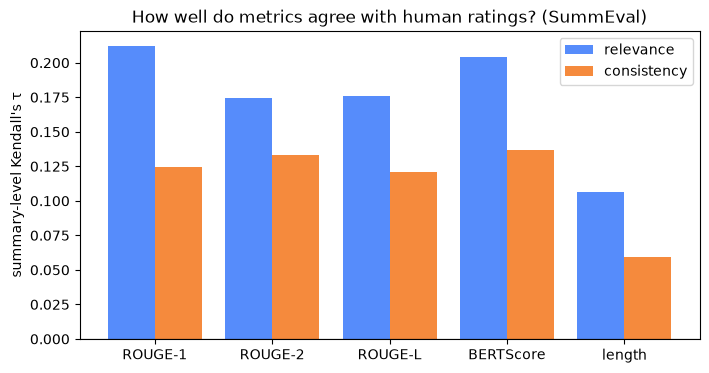

In [69]:
x = np.arange(len(metric_names))
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(x - 0.2, [correlations[n][0] for n in metric_names], width=0.4, label="relevance")
ax.bar(x + 0.2, [correlations[n][1] for n in metric_names], width=0.4, label="consistency")
ax.set_xticks(x, metric_names)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("summary-level Kendall's τ")
ax.set_title("How well do metrics agree with human ratings? (SummEval)")
ax.legend()
plt.show()

**5.3 Interpret the correlations.**
1. How strong are the correlations? Is any metric clearly better than counting words?
2. Which dimension do the metrics capture better, relevance or consistency? Why would it be hard for *any* metric that compares a summary with a **reference** to measure consistency?
3. A paper reports that its new summariser beats the old one by 0.5 ROUGE-L points. What would you want to know before believing that it produces better summaries?

---

*Your answer here:*

---

### Optional: more references

With more references, a metric sees more of the ways in which a good summary can be written. Re-run Part 5 with `N_REFS = 1` and `N_REFS = 11` (all references). How do the correlations change? Which metric profits the most?

In [ ]:
# Your exploration here

> **The `evaluate` library.** Hugging Face's [`evaluate`](https://huggingface.co/docs/evaluate) library wraps these and many other metrics behind one interface, `evaluate.load("rouge")`, `evaluate.load("bleu")`, `evaluate.load("bertscore")`, ..., and is a convenient way to compute them in your project. Under the hood it calls the same packages that we used here. Whatever tool you use, report exactly which implementation and settings you used: tokenization and smoothing alone can change a BLEU score by several points ([Post, 2018](https://aclanthology.org/W18-6319/)).

## 6. MCQ

Answer each question by writing the letter of your choice (A–D) after **Answer:**.

---

### 6.1. Clipping

A candidate translation is `the the the the the the the` and the reference is `the cat is on the mat`. What is its clipped unigram precision?

A. 7/7<br>
B. 2/7<br>
C. 1/7<br>
D. 2/6<br>

**Answer:**

B.

---

### 6.2. Brevity penalty

Why does BLEU multiply the score by a brevity penalty?

A. To punish candidates that are longer than the reference<br>
B. Because BLEU is based on precision, which on its own would reward candidates that leave out most of the content<br>
C. To make BLEU symmetric between candidate and reference<br>
D. To correct for the smoothing of zero counts<br>

**Answer:**

B.

---

### 6.3. ROUGE-L

The reference is `the police arrested the man` and the prediction is `the man arrested the police`. Which statement is correct?

A. ROUGE-1 F1 is 1.0, and ROUGE-L F1 is lower than 1.0<br>
B. ROUGE-1 and ROUGE-L are both 1.0, because the same words are used<br>
C. ROUGE-L is 1.0, because the longest common subsequence covers all words<br>
D. Both are 0, because the meaning is different<br>

**Answer:**

A.

---

### 6.4. BERTScore

How does BERTScore compute its **recall**?

A. The fraction of reference n-grams that also occur in the candidate<br>
B. The cosine similarity between the mean embedding of the candidate and the mean embedding of the reference<br>
C. For every reference token, the highest cosine similarity with any candidate token, averaged over the reference tokens<br>
D. The probability that BERT assigns to the reference given the candidate<br>

**Answer:**

C.

---

### 6.5. Meta-evaluation

How do researchers usually decide whether an automatic metric is good?

A. By checking that it gives a score of 1.0 to the reference itself<br>
B. By measuring how well its scores correlate with human judgements of the same outputs<br>
C. By checking that larger models get higher scores<br>
D. By measuring how fast it can be computed<br>

**Answer:**

B.